"C:\Users\Dell\Documents\Downloads\stores_sales_forecasting.csv"

**Step 1: import libraries**

In [10]:
# data handling
import joblib 
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

# regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

# metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

**Step 2: load dataset**

In [11]:
df = pd.read_csv("stores_sales_forecasting.csv", encoding="utf-8", encoding_errors="ignore")

**Step 3: understand your data**

In [12]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [13]:
df.sample(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1866,8777,CA-2016-102813,7/2/2016,7/3/2016,First Class,EA-14035,Erin Ashbrook,Corporate,United States,Huntsville,...,77340,Central,FUR-CH-10000665,Furniture,Chairs,"Global Airflow Leather Mesh Back Chair, Black",528.430,5,0.3,0.000
542,2615,CA-2014-147298,4/26/2014,5/3/2014,Standard Class,AG-10300,Aleksandra Gannaway,Corporate,United States,Los Angeles,...,90049,West,FUR-CH-10004886,Furniture,Chairs,Bevis Steel Folding Chairs,230.280,3,0.2,23.028
392,1876,US-2016-112977,3/10/2016,3/16/2016,Standard Class,CJ-12010,Caroline Jumper,Consumer,United States,Long Beach,...,11561,East,FUR-BO-10003272,Furniture,Bookcases,O'Sullivan Living Dimensions 5-Shelf Bookcases,176.784,1,0.2,-22.098
1972,9322,US-2016-111563,11/4/2016,11/8/2016,Standard Class,SM-20005,Sally Matthias,Consumer,United States,Houston,...,77041,Central,FUR-FU-10002445,Furniture,Furnishings,"DAX Two-Tone Rosewood/Black Document Frame, De...",11.376,3,0.6,-5.688
618,2945,CA-2017-126242,11/19/2017,11/24/2017,Standard Class,MC-18100,Mick Crebagga,Consumer,United States,Los Angeles,...,90049,West,FUR-FU-10002685,Furniture,Furnishings,"Executive Impressions 13-1/2"" Indoor/Outdoor W...",18.700,1,0.0,7.106


In [14]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [15]:
df.nunique()

Row ID           2121
Order ID         1764
Order Date        889
Ship Date         960
Ship Mode           4
Customer ID       707
Customer Name     707
Segment             3
Country             1
City              371
State              48
Postal Code       454
Region              4
Product ID        375
Category            1
Sub-Category        4
Product Name      380
Sales            1636
Quantity           14
Discount           11
Profit           1777
dtype: int64

In [16]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   str    
 2   Order Date     2121 non-null   str    
 3   Ship Date      2121 non-null   str    
 4   Ship Mode      2121 non-null   str    
 5   Customer ID    2121 non-null   str    
 6   Customer Name  2121 non-null   str    
 7   Segment        2121 non-null   str    
 8   Country        2121 non-null   str    
 9   City           2121 non-null   str    
 10  State          2121 non-null   str    
 11  Postal Code    2121 non-null   int64  
 12  Region         2121 non-null   str    
 13  Product ID     2121 non-null   str    
 14  Category       2121 non-null   str    
 15  Sub-Category   2121 non-null   str    
 16  Product Name   2121 non-null   str    
 17  Sales          2121 non-null   float64
 18  Quantity       2121

In [18]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000
mean,5041.643564,55726.556341,349.834887,3.785007,0.173923,8.699327
std,2885.740258,32261.888225,503.179145,2.251620,0.181547,136.049246
min,1.000000,1040.000000,1.892000,1.000000,0.000000,-1862.312400
25%,2568.000000,22801.000000,47.040000,2.000000,0.000000,-12.849000
50%,5145.000000,60505.000000,182.220000,3.000000,0.200000,7.774800
75%,7534.000000,90032.000000,435.168000,5.000000,0.300000,33.726600
max,9991.000000,99301.000000,4416.174000,14.000000,0.700000,1013.127000


In [19]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

**Step 4: Data cleaning**

In [21]:
# 1. remove null values
# df.dropna(inplace=True)

In [22]:
# 2. remove duplicates
# df.drop_duplicates(inplace=True)

In [23]:
# 3. fix data types
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%Y-%m-%d', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%Y-%m-%d', errors='coerce')

In [24]:
# 4. fix column names
rename_dict = {
    'Order Date': 'order_date',
    'Ship Date': 'ship_date',
    'Ship Mode': 'ship_mode',
    'Customer Name': 'customer_name',
    'Product Name': 'product_name',
    'Segment': 'segment',
    'Country': 'country',
    'City': 'city',
    'State': 'state',
    'Region': 'region',
    'Category': 'category',
    'Sub-Category': 'sub_category',
    'Sales': 'sales',
    'Quantity': 'quantity',
    'Discount': 'discount',
    'Profit': 'profit'
}
df.rename(columns=rename_dict, inplace=True)

In [25]:
# remove unwanted cols
df.drop(columns=['Row ID', 'Order ID','Customer ID','Product ID','Postal Code'], inplace=True)

In [26]:
df.drop(columns=['order_date', 'ship_date'], inplace=True)

In [27]:
df.drop(columns=['country'], inplace=True)

In [28]:
# 5. remove outliers
numeric_cols = ['sales', 'quantity', 'discount', 'profit']
for i,col in enumerate(numeric_cols):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    print(f"\n{i}: {col}")
    before_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"before outliers: {len(before_outliers)}")
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    after_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"after outliers: {len(after_outliers)}")



0: sales
before outliers: 164
after outliers: 0

1: quantity
before outliers: 24
after outliers: 0

2: discount
before outliers: 0
after outliers: 0

3: profit
before outliers: 336
after outliers: 0


**Step 5: Feature engineering**

In [29]:
df['profit_margin'] = df['profit'] / df['sales']
df['sales_per_quantity'] = df['sales'] / df['quantity']
df['discount_amount'] = df['sales'] * df['discount']
df['profit_per_quantity'] = df['profit'] / df['quantity']
df['quantity_discount'] = df['quantity'] * df['discount']

**Step 6: Data visualization**

Univariate:

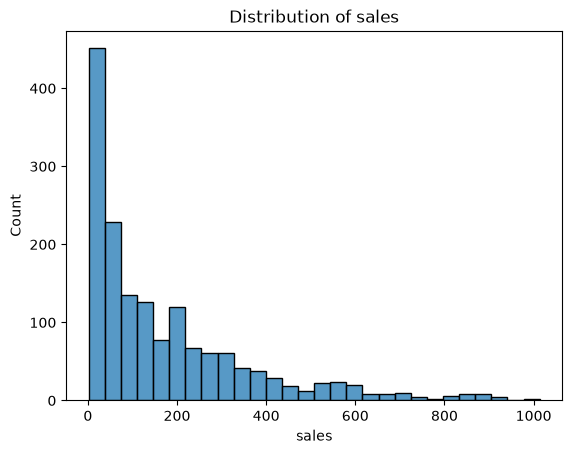

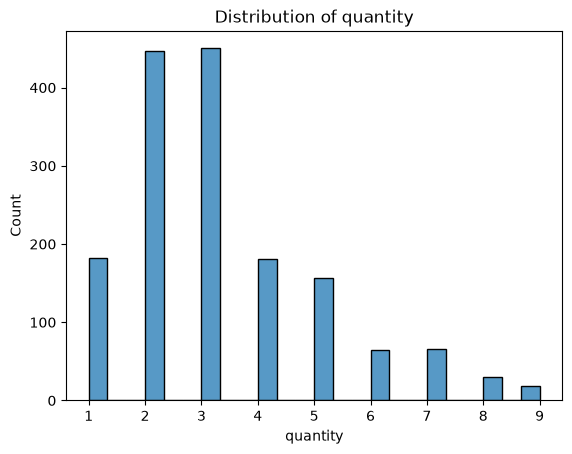

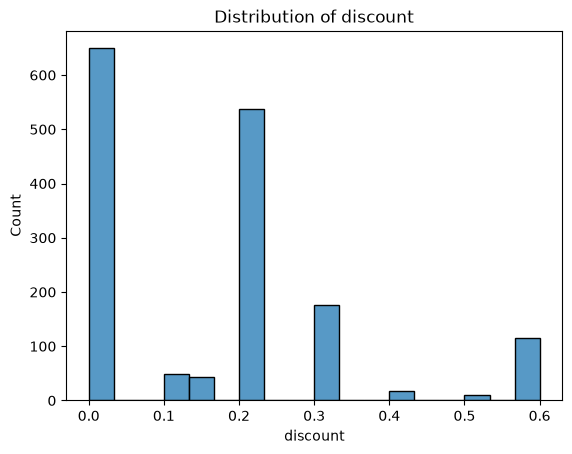

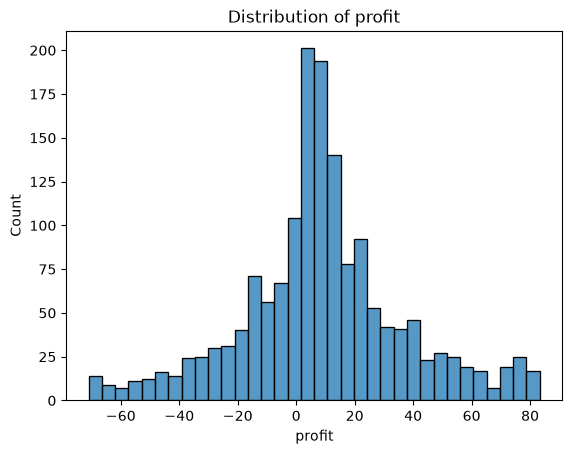

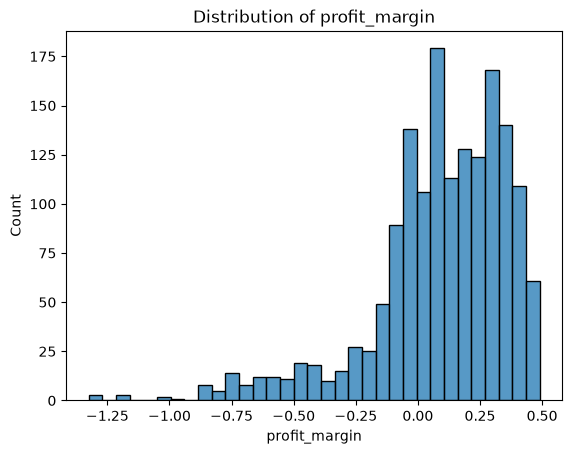

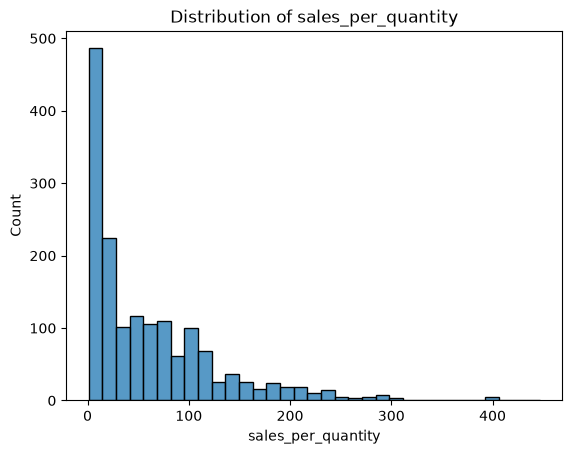

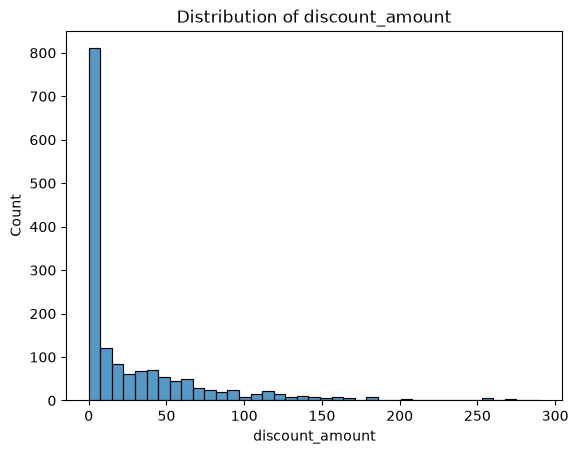

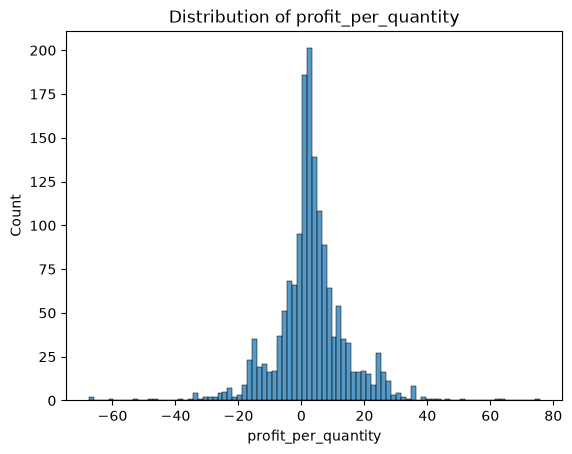

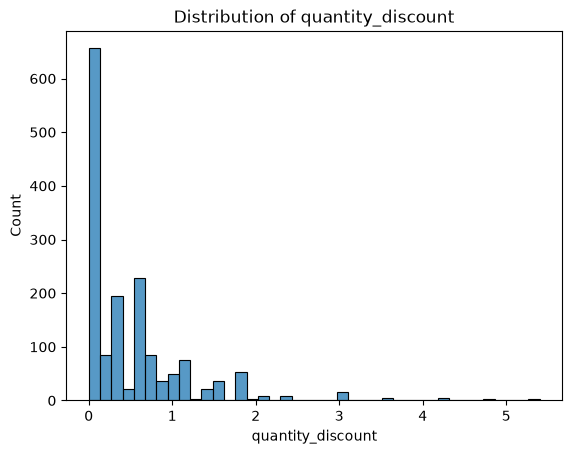

In [36]:
nums = ['sales', 'quantity','discount', 'profit', 'profit_margin', 'sales_per_quantity','discount_amount', 'profit_per_quantity', 'quantity_discount']
for n in nums:
    sns.histplot(data=df, x=n)
    plt.title(f'Distribution of {n}')
    plt.show()

In [31]:
df['category'].value_counts()

category
Furniture    1597
Name: count, dtype: int64

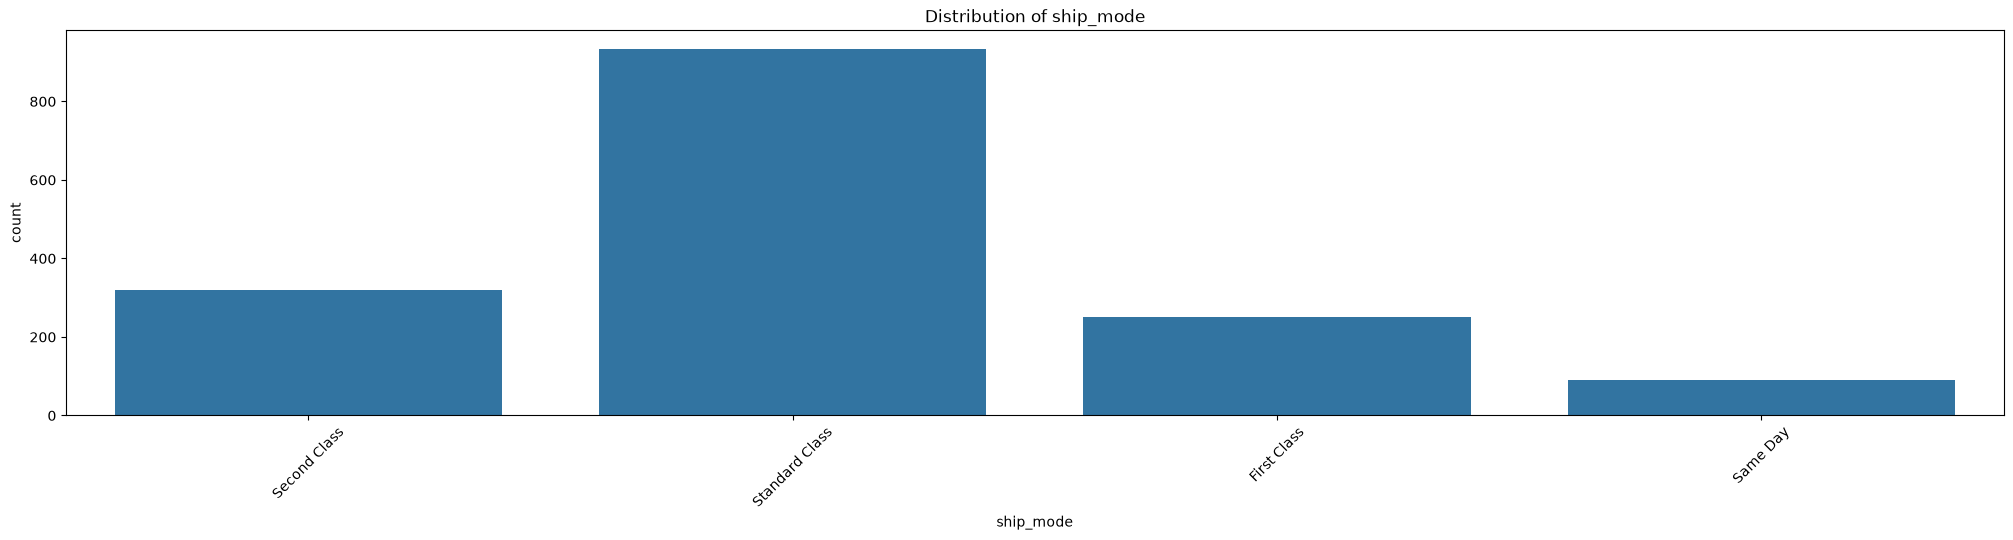

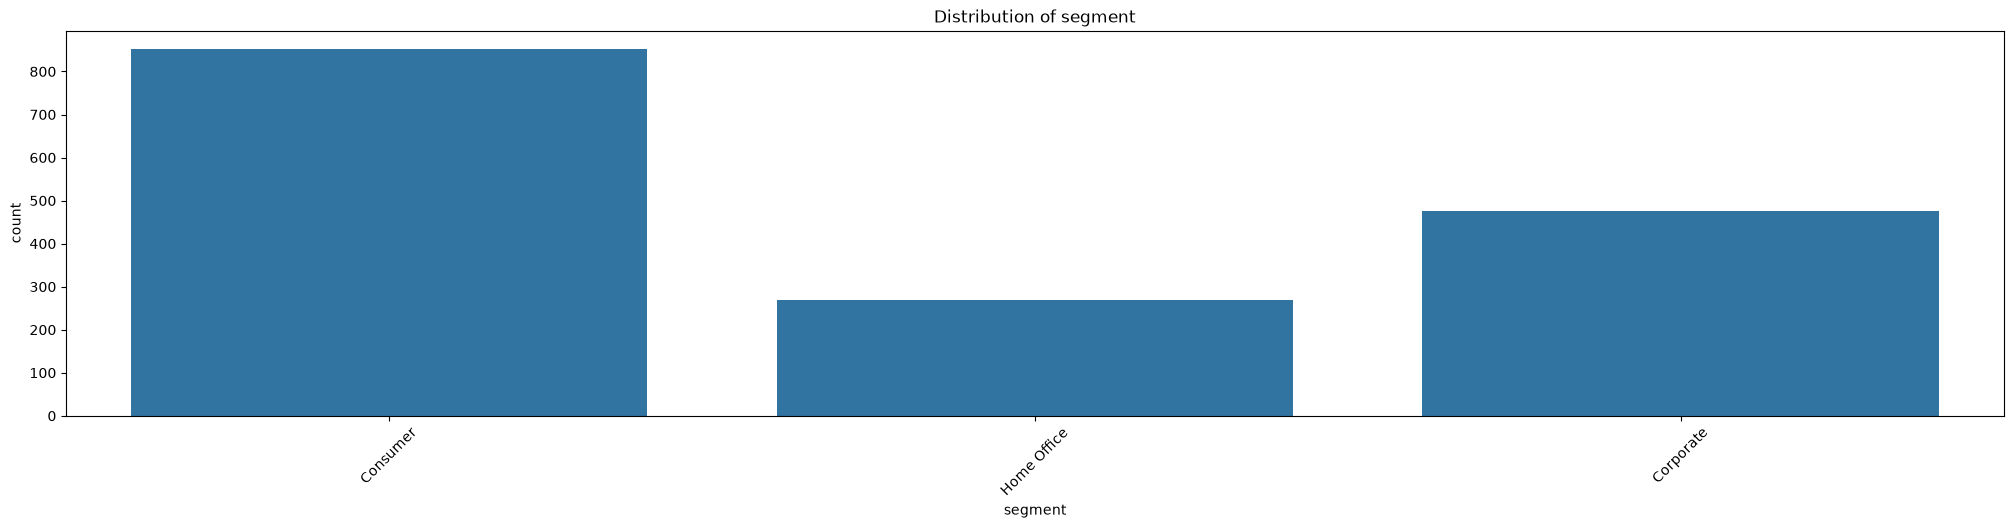

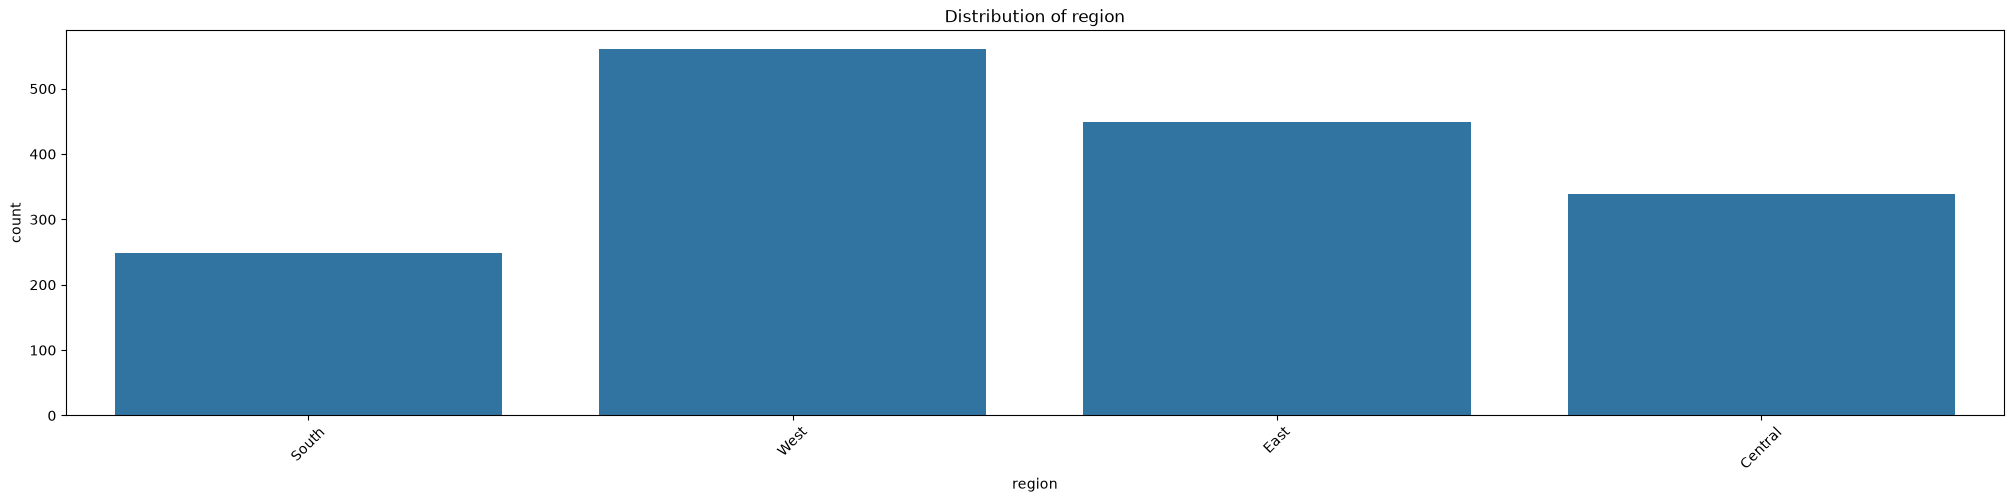

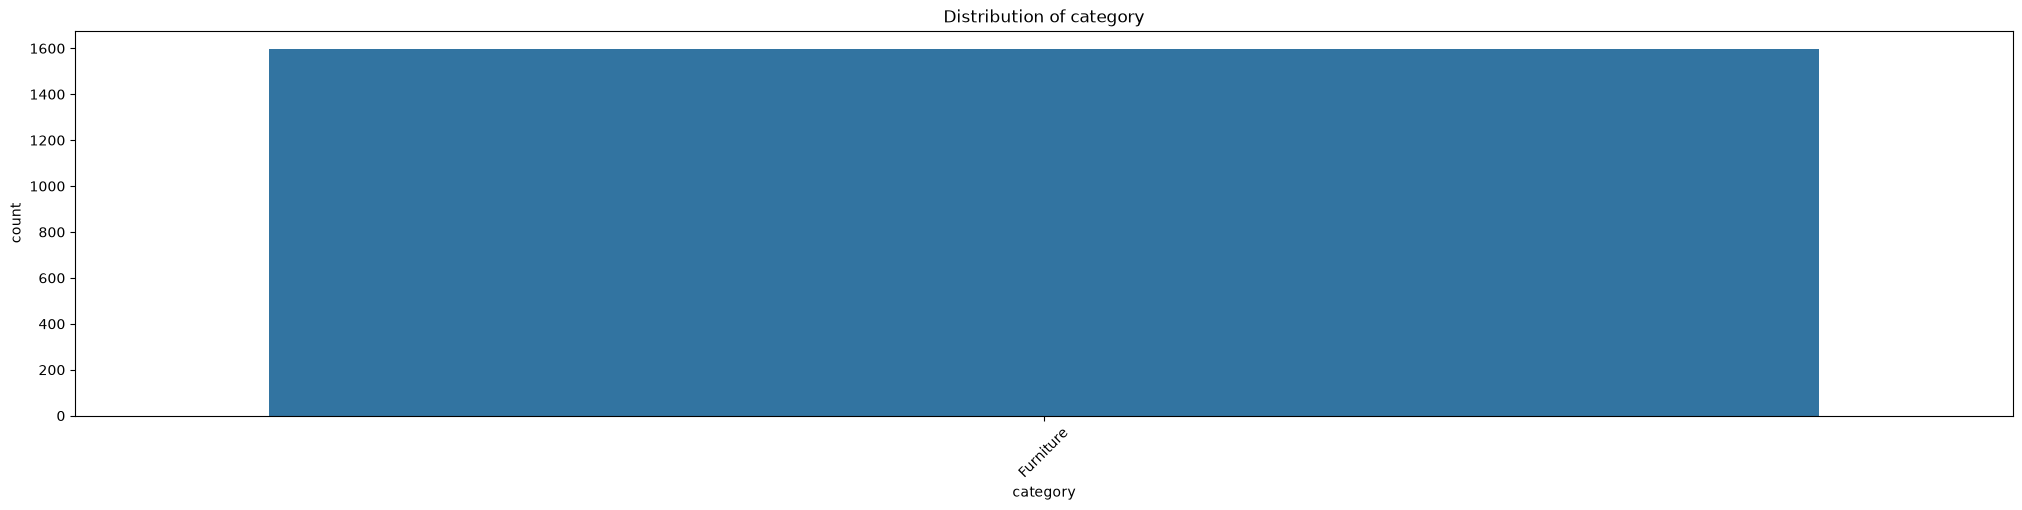

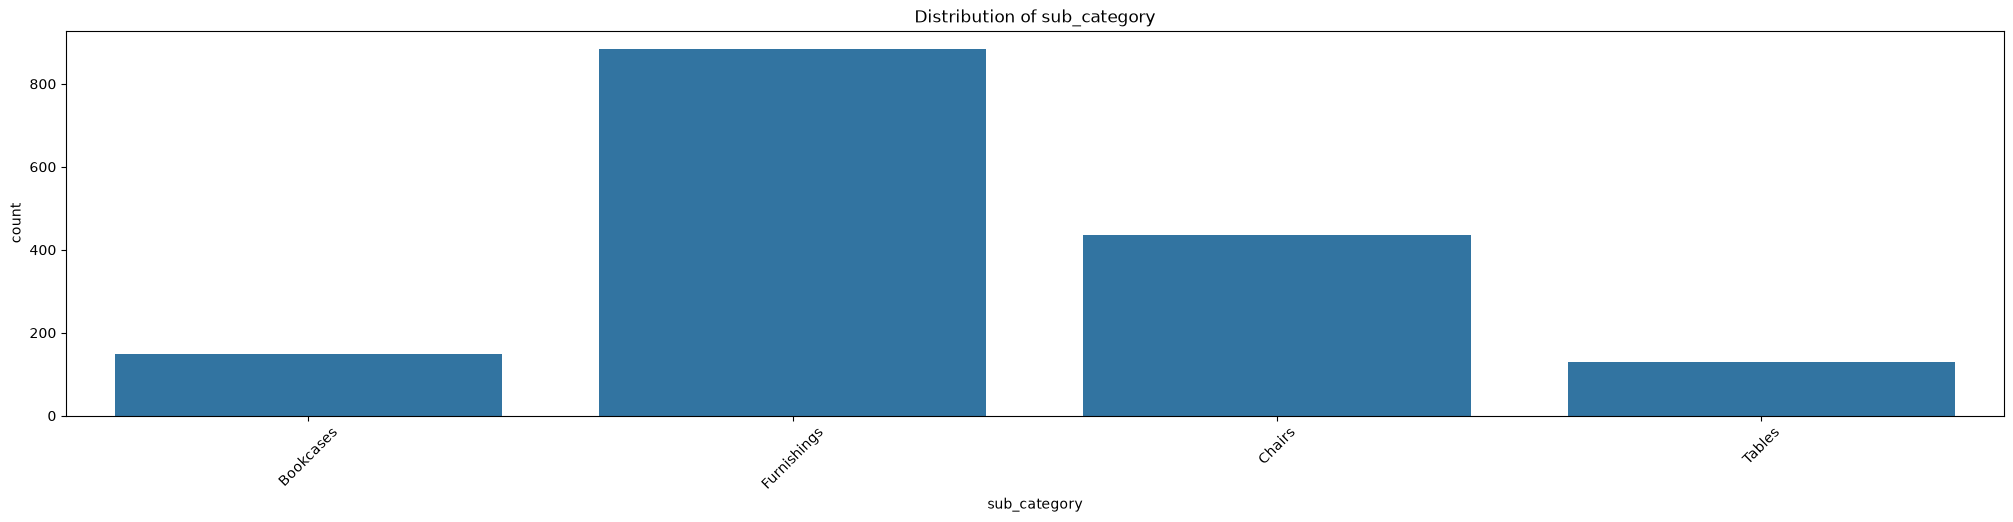

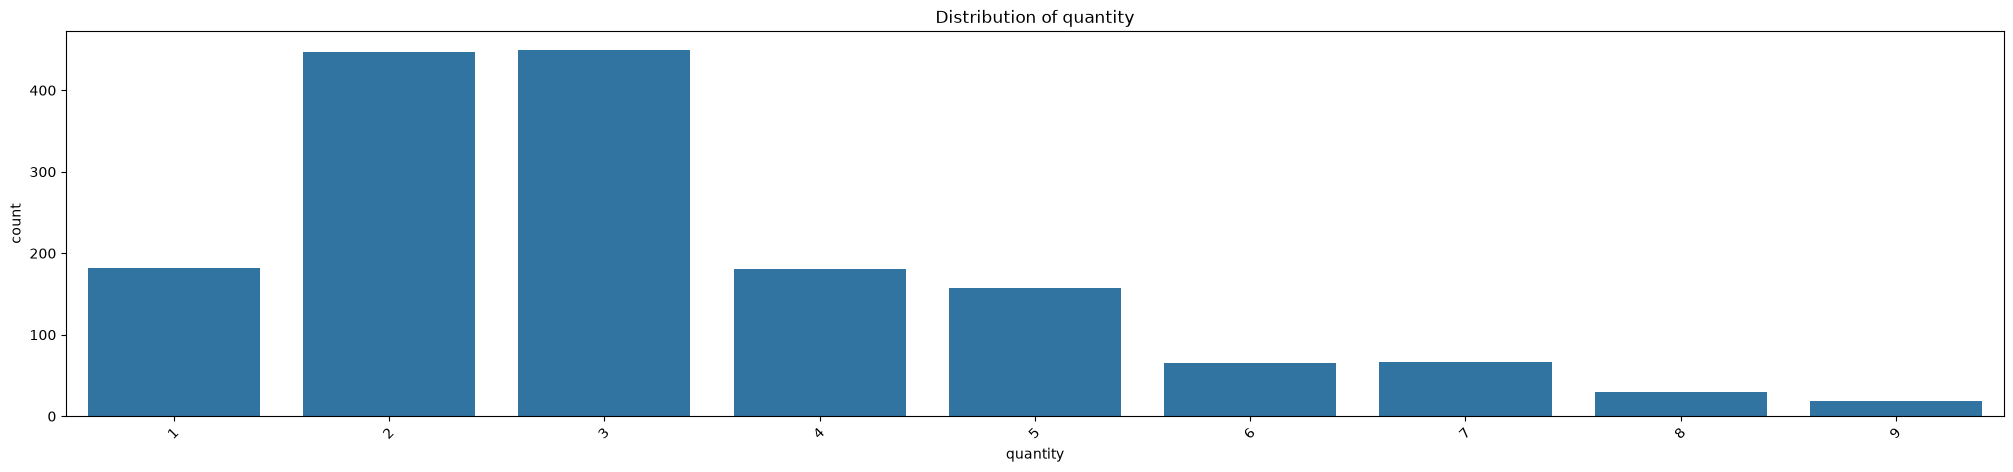

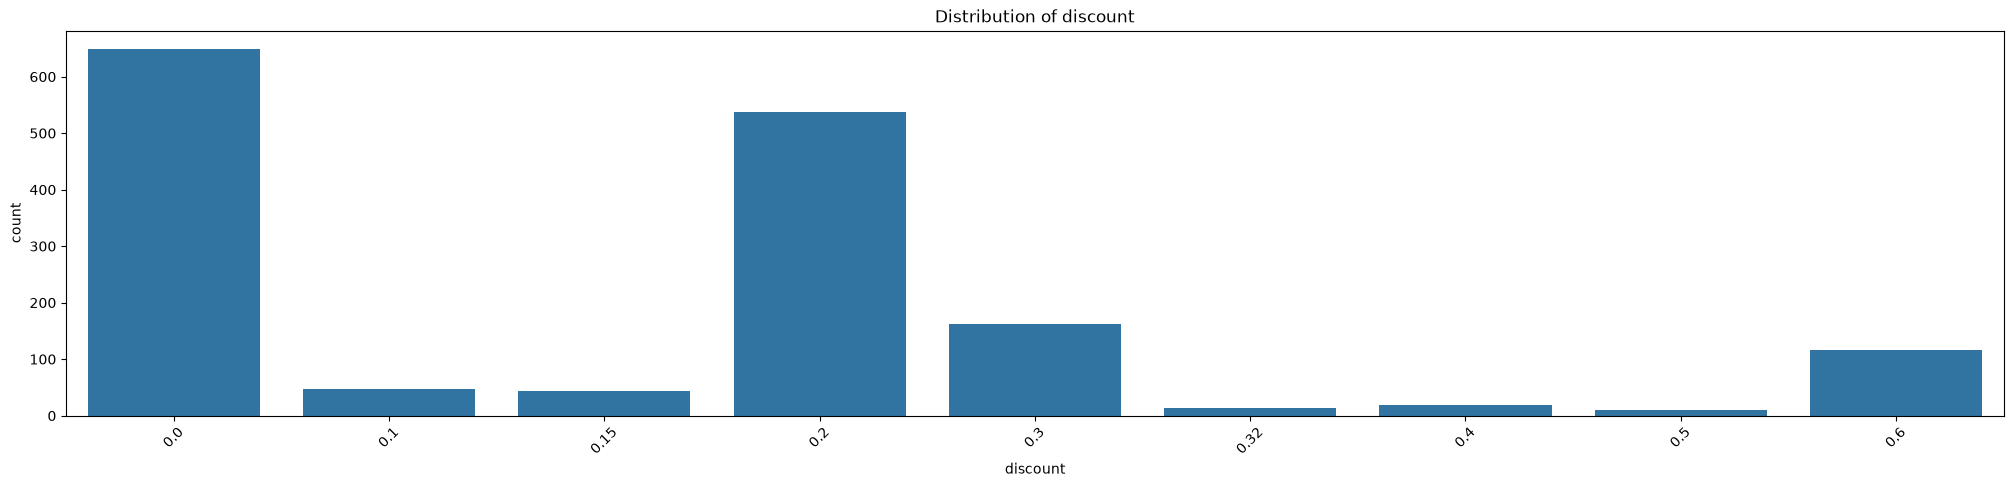

In [38]:
nums = ['ship_mode','segment','region','category', 'sub_category','quantity','discount']
for n in nums:
    plt.figure(figsize=(25,5))
    sns.countplot(data=df, x=n)
    plt.title(f'Distribution of {n}')
    plt.xticks(rotation=45)
    plt.show()

Bivariate:

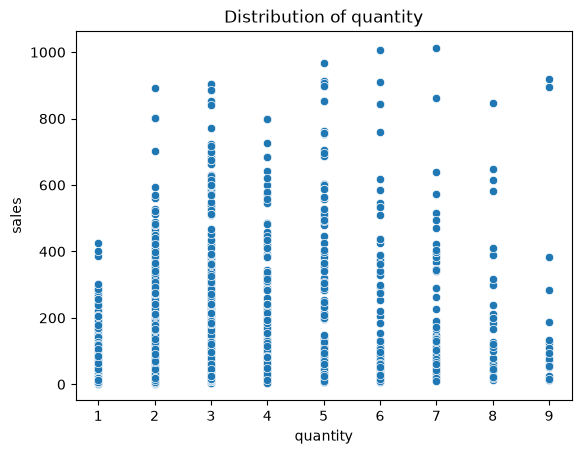

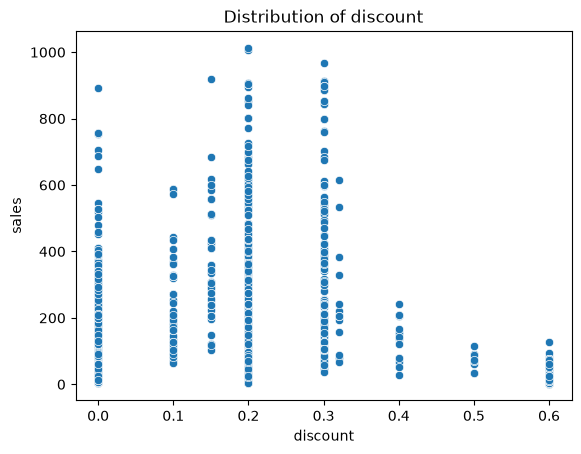

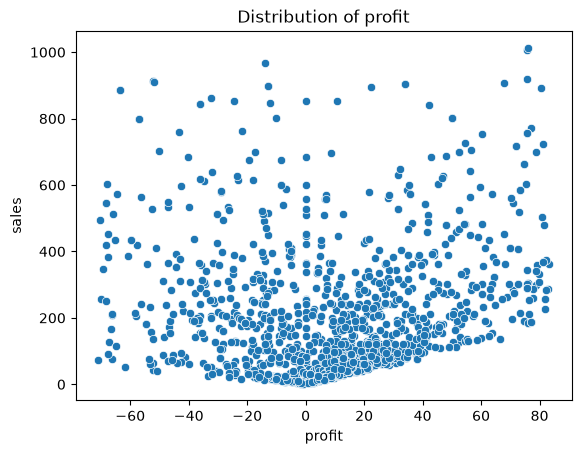

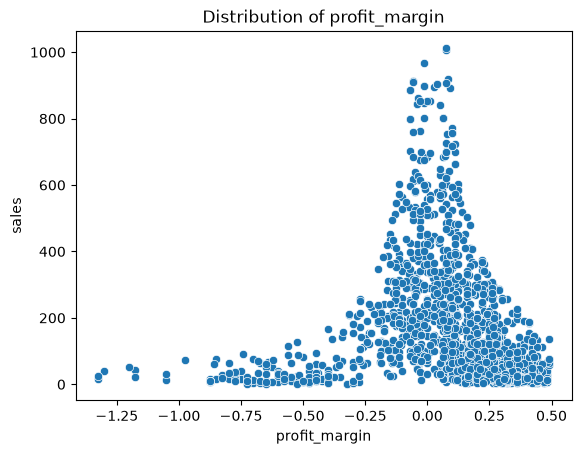

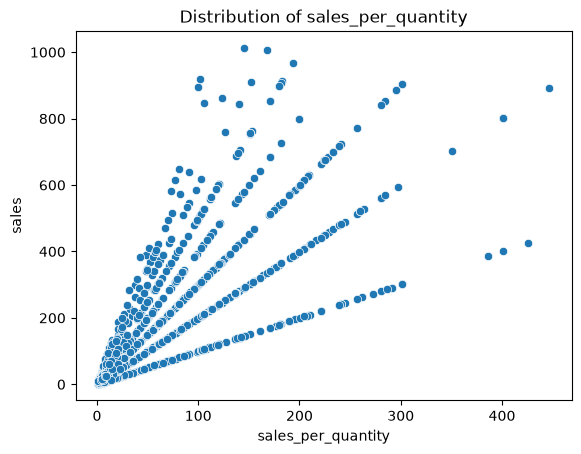

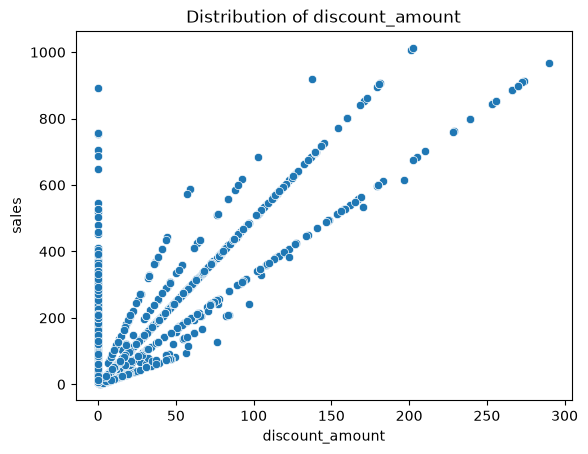

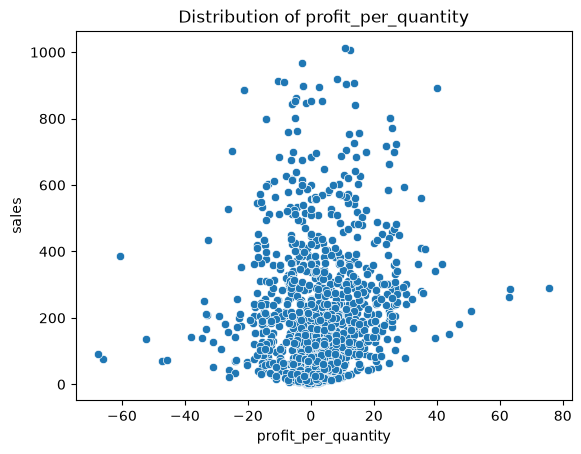

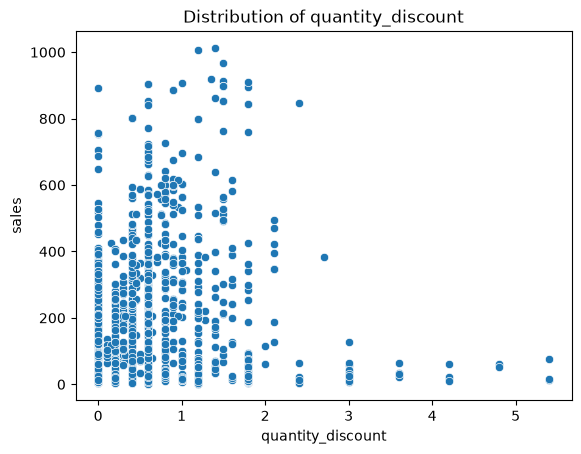

In [41]:
nums = ['quantity','discount', 'profit', 'profit_margin', 'sales_per_quantity','discount_amount', 'profit_per_quantity', 'quantity_discount']
for n in nums:
    sns.scatterplot(data=df, x=n, y='sales')
    plt.title(f'Distribution of {n}')
    plt.show()

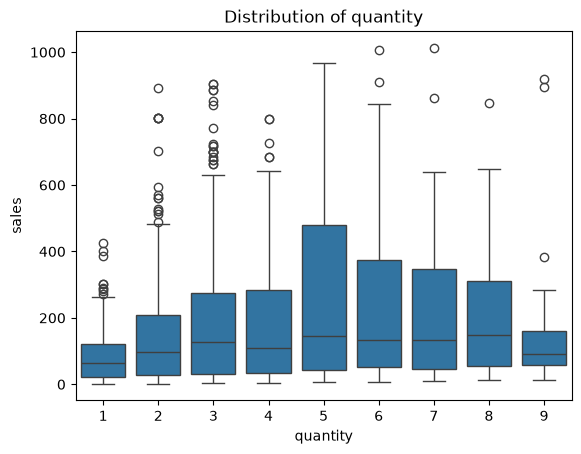

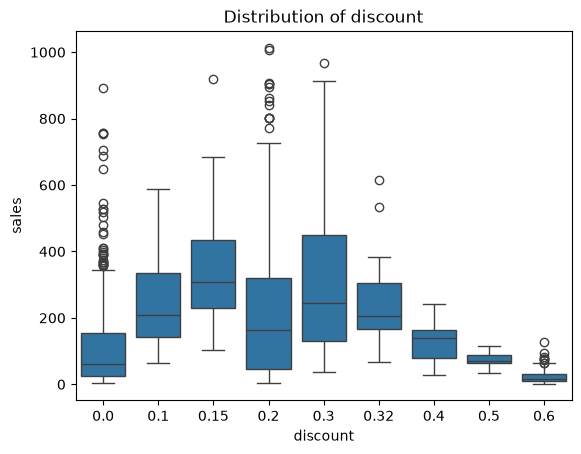

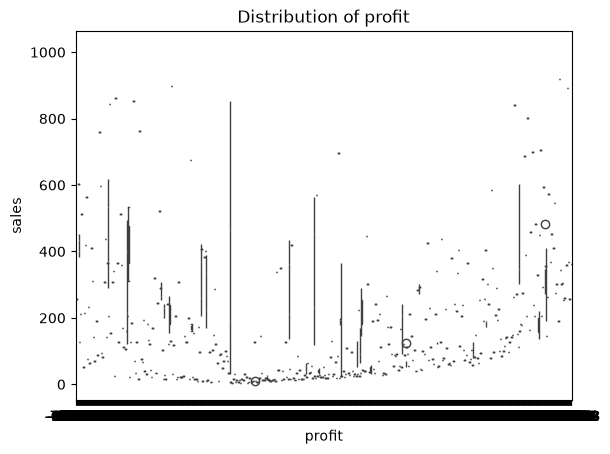

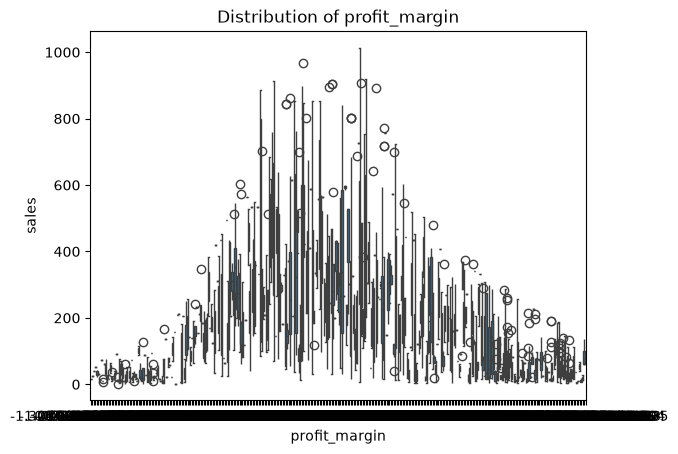

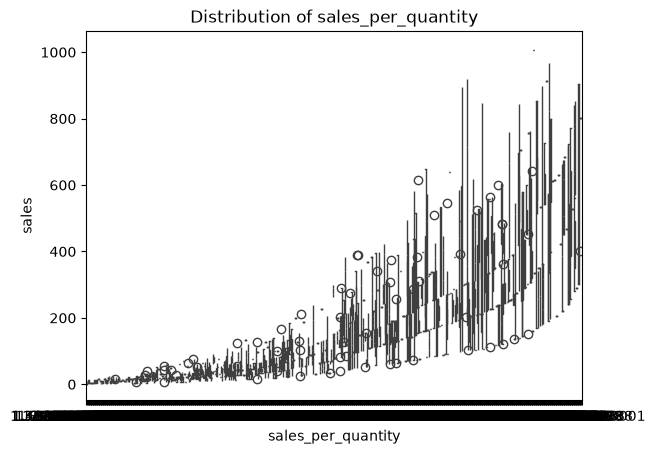

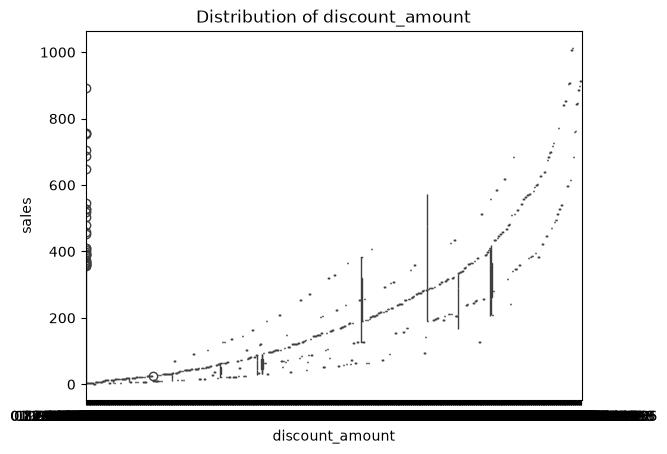

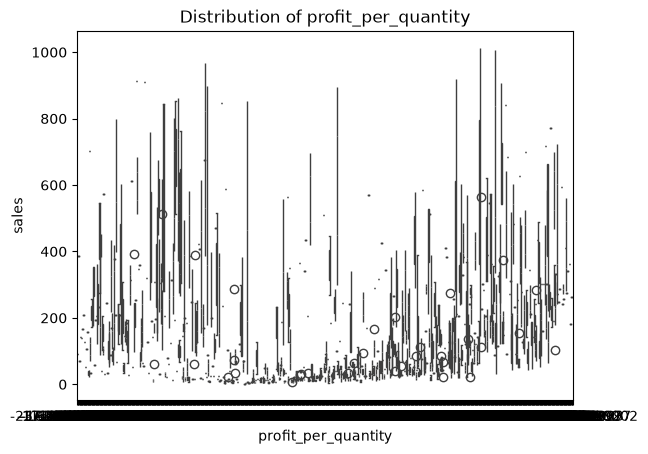

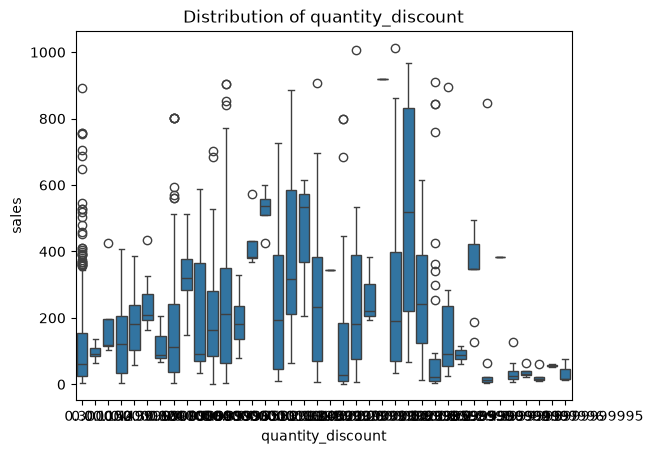

In [45]:
cat = ['ship_mode','segment','category', 'sub_category']
for n in nums:
    sns.boxplot(data=df, x=n, y='sales')
    plt.title(f'Distribution of {n}')
    plt.show()

**Step 7: define feature and target**

In [47]:
X = df.drop(columns=['sales'])
y = df['sales']

num_cols = df.select_dtypes(include=[int,float]).drop(columns=['sales']).columns.to_list()
cat_cols = df.select_dtypes(include=[str]).columns.to_list()

**Step 8: train-test-split**

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (1277, 17) | X_test: (320, 17)


**Step 9: Preprocessing pipeline**

In [54]:
num_trans = Pipeline([
    ('imp',SimpleImputer(strategy="mean")),
    ('scr',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy="most_frequent")),
    ('ohe',OneHotEncoder(sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num_pre",num_trans,num_cols),
    ("cat_pre",cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [55]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

**Step 10: Feature selection**

In [56]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_df)
X_test_sele = selector.transform(X_test_df)
print("X_train Shape before feature selection: ",X_train_df.shape)
print("X_train Shape after feature selection: ",X_train_sele.shape)
print("\nX_test Shape before feature selection: ",X_test_df.shape)
print("X_test Shape after feature selection: ",X_test_sele.shape)

X_train Shape before feature selection:  (1277, 1315)
X_train Shape after feature selection:  (1277, 55)

X_test Shape before feature selection:  (320, 1315)
X_test Shape after feature selection:  (320, 55)


**Step 11&12: Model training & Evaluation**

In [57]:
models = {
    "Linear regression":LinearRegression(),
    "Decision Tree":DecisionTreeRegressor(max_depth=15, min_samples_split=5, min_samples_leaf=3),
    "Random Forest":RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_split=4, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "Gradient Boosting":GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42),
    "XgBoost":XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=7, random_state=42)
}

for name,model in models.items():
    model.fit(X_train_sele,y_train)
    y_pred = model.predict(X_test_sele)
    
    r2 = r2_score(y_test,y_pred)
    mae = mean_absolute_error(y_test,y_pred)
    mse = mean_squared_error(y_test,y_pred)
    print(f"[{name}] -> r2: {r2*100:.2f}% | mae: {mae:.2f} | mse: {mse:.2f}")

[Linear regression] -> r2: 95.09% | mae: 31.81 | mse: 2097.19
[Decision Tree] -> r2: 99.03% | mae: 9.31 | mse: 415.73
[Random Forest] -> r2: 99.40% | mae: 6.75 | mse: 257.60
[Gradient Boosting] -> r2: 99.46% | mae: 6.37 | mse: 230.10
[XgBoost] -> r2: 99.32% | mae: 6.67 | mse: 292.45


**Step 13: Cross Validation**

In [59]:
xg_validator = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42)
cv_score = cross_val_score(xg_validator, X_train_sele, y_train, cv=3, scoring='r2')
print("3-Fold cross validation r2 matric: ",cv_score)
print(f"cross validation score: {cv_score.mean():.2f}")

3-Fold cross validation r2 matric:  [0.97877574 0.99273585 0.96502742]
cross validation score: 0.98


**Step 14: Hyperparameter Tuning**

In [60]:
param_distribution = {
    'n_estimators': [150, 200, 250],
    'learning_rate': [0.05, 0.01, 0.1],
    'max_depth': [6, 7, 8]
}

random_search = RandomizedSearchCV(
    estimator=xg_validator,
    param_distributions=param_distribution,
    cv=3,
    scoring='r2',
    n_iter=3,
    n_jobs=-1
)

random_search.fit(X_train_sele,y_train)
best_tuned_regressor = random_search.best_estimator_

print("Best parameters: ",random_search.best_params_)
print("Best score: ",random_search.best_score_)

Best parameters:  {'n_estimators': 250, 'max_depth': 6, 'learning_rate': 0.1}
Best score:  0.9795510960005768


In [66]:
check_regressor = GradientBoostingRegressor(n_estimators=250, learning_rate=0.1, max_depth=6, random_state=42)
check_regressor.fit(X_train_sele,y_train)     
y_pred = check_regressor.predict(X_test_sele)          
print(f"XgBoost Verification Test r2 score: {r2_score(y_test, y_pred)*100:.2f}%")

XgBoost Verification Test r2 score: 99.53%


**Step 15: Feature Importance**

In [61]:
importance = pd.DataFrame({
    "features": X_train_df.columns[selector.get_support()],
    "importance": best_tuned_regressor.feature_importances_
})

print("---Top feature importance score---")
print(importance.head(10))

---Top feature importance score---
                         features  importance
0               num_pre__quantity    0.061124
1               num_pre__discount    0.031998
2                 num_pre__profit    0.021183
3          num_pre__profit_margin    0.009512
4     num_pre__sales_per_quantity    0.249549
5        num_pre__discount_amount    0.624395
6    num_pre__profit_per_quantity    0.000650
7      num_pre__quantity_discount    0.000248
8  cat_pre__ship_mode_First Class    0.000011
9     cat_pre__ship_mode_Same Day    0.000010


**Step 16: Final Pipeline Production**

In [62]:
final_production_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("selector",selector),
    ("regressor",best_tuned_regressor)
])
final_production_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['ship_mode','customer_name','segment',...,'discount_amount', 'profit_per_quantity','quantity_discount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_pre', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be aut

**Step 17: Save and load model**

In [63]:
save_payload = {
    "final_pipeline": final_production_pipeline,
    "feature_name": X_train_df.columns[selector.get_support()]
}
joblib.dump(save_payload,"xgboost_pipeline.pkl")
print("Model saved successfully!")

Model saved successfully!


In [64]:
joblib.load("xgboost_pipeline.pkl")
print("Model saved successfully!")

Model saved successfully!
